<a href="https://colab.research.google.com/github/Ryan-T-Monash/MMA3001-Project/blob/main/notebooks/Main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Main: data preparation and performance
Bearing remaining-life project (MMA3001), NASA IMS data. Run top to bottom. The modelling is in `Data Analysis.ipynb`.

## 1. Setup

In [41]:
# ---- Setup: run every time a new session starts ----
from google.colab import drive, userdata
import os, sys
drive.mount("/content/drive")
PROJECT = "/content/drive/MyDrive/MMA3001/MMA3001_Project"   # raw IMS data (Main only)
try:
    AUTH = f"oauth2:{userdata.get('GH_PAT')}@"              # only needed to push
except Exception:
    AUTH = ""                                                # no secret: read-only clone
%cd /content
if not os.path.isdir("/content/repo"):
    !git clone -q https://{AUTH}github.com/Ryan-T-Monash/MMA3001-Project.git repo
else:
    !git -C /content/repo pull -q origin main
%cd /content/repo
!git config user.name "Ryan"
!git config user.email "Ryan-T-Monash@users.noreply.github.com"
!pip install -q -r requirements.txt
sys.path.insert(0, "/content/repo/src")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content
/content/repo


In [32]:
!unzip -l "{PROJECT}/IMS.zip"
!unzip -o -j -q "{PROJECT}/IMS.zip" "*3rd_test*" -d /content/t3
!apt-get -qq install -y unrar > /dev/null
!ls /content/t3
!unrar lb /content/t3/*3rd_test* | grep -c "\."

Archive:  /content/drive/MyDrive/MMA3001/MMA3001_Project/IMS.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
        0  2023-11-02 16:33   IMS/
      312  2023-11-02 16:33   __MACOSX/._IMS
366567310  2007-09-18 07:44   IMS/1st_test.rar
      212  2007-09-18 07:44   __MACOSX/IMS/._1st_test.rar
   400443  2012-10-10 04:26   IMS/Readme Document for IMS Bearing Data.pdf
      212  2012-10-10 04:26   __MACOSX/IMS/._Readme Document for IMS Bearing Data.pdf
 85581092  2007-09-18 13:54   IMS/2nd_test.rar
      212  2007-09-18 13:54   __MACOSX/IMS/._2nd_test.rar
609047134  2017-07-18 22:33   IMS/3rd_test.rar
      212  2017-07-18 22:33   __MACOSX/IMS/._3rd_test.rar
---------                     -------
1061597139                     10 files
3rd_test.rar
6324


In [2]:
# Which IMS test this notebook works on: change it only here
TEST = "2nd_test"                                   # "1st_test", "2nd_test" or "3rd_test"
TEST_DIR = f"{PROJECT}/IMS/IMS/{TEST}/{TEST}"
# Failed bearing per test: (channel index from 0, fault frequency to track)
FAILED = {"1st_test": (4, "BPFI"),                  # bearing 3, inner race
          "2nd_test": (0, "BPFO"),                  # bearing 1, outer race
          "3rd_test": (2, "BPFO")}                  # bearing 3, outer race
CHANNEL, FAULT = FAILED[TEST]
print(TEST, "| channel", CHANNEL, "|", FAULT)

2nd_test | channel 0 | BPFO


## 2. Features (RMS, kurtosis, peak per channel)

In [3]:
# ---- Features: load the saved table, or build it once from the raw files (slow) ----
import shutil
import pandas as pd
from bearing_features import list_snapshot_files, extract_features

FEATURES_CSV = f"{PROJECT}/features_{TEST}.csv"     # Drive cache
REPO_CSV = f"/content/repo/data/features_{TEST}.csv"
if os.path.exists(FEATURES_CSV):
    features = pd.read_csv(FEATURES_CSV, index_col="sample")
elif os.path.exists(REPO_CSV):                       # no Drive cache: use the copy in the repo
    features = pd.read_csv(REPO_CSV, index_col="sample")
else:
    files = list_snapshot_files(TEST_DIR)
    print(f"Processing {len(files)} files...")
    features = extract_features(files, save_to=FEATURES_CSV)
if os.path.exists(FEATURES_CSV):
    os.makedirs("/content/repo/data", exist_ok=True)
    shutil.copy(FEATURES_CSV, REPO_CSV)
print(len(features), "snapshots")
features.head()

984 snapshots


,file,rms_1,kurtosis_1,peak_1,rms_2,kurtosis_2,peak_2,rms_3,kurtosis_3,peak_3,rms_4,kurtosis_4,peak_4
sample,,,,,,,,,,,,,
0,2004.02.12.10.32.39,0.074179,3.628763,0.454,0.090944,3.506801,0.513,0.109404,6.213075,1.023,0.054103,3.065959,0.264
1,2004.02.12.10.42.39,0.075382,3.648291,0.388,0.093419,3.253014,0.481,0.109817,4.395250,0.752,0.056101,3.107539,0.249
2,2004.02.12.10.52.39,0.076230,3.513475,0.503,0.093718,3.310789,0.503,0.109861,5.639948,0.933,0.056145,3.257236,0.354
3,2004.02.12.11.02.39,0.078724,4.157953,0.608,0.092947,3.235341,0.569,0.110667,5.682779,1.016,0.056807,3.806190,0.525
4,2004.02.12.11.12.39,0.078474,3.603177,0.391,0.095348,3.226309,0.486,0.107506,4.578395,0.771,0.056841,3.138954,0.244


## 3. Data quality

In [4]:
# ---- Data quality: timestamps, gaps and unreadable or odd snapshots (needs the raw files) ----
from data_quality import file_times, time_gaps, quality_report
files = list_snapshot_files(TEST_DIR)
print(len(files), "files")
print("gaps:")
print(time_gaps(file_times(files)))
report = quality_report(files, step=10)            # every 10th file; step=1 checks all
print(report.sum(numeric_only=True))
report.tail()

984 files
gaps:
Empty DataFrame
Columns: [after_sample, start, end, gap_minutes]
Index: []
unreadable             0
n_samples        2048000
n_channels           400
wrong_length           0
n_nan                  0
flat_channels          0
max_at_peak         7973
dtype: int64


,file,unreadable,n_samples,n_channels,wrong_length,n_nan,flat_channels,max_at_peak
sample,,,,,,,,
950,2004.02.19.00.52.39,False,20480,4,False,0,0,2
960,2004.02.19.02.32.39,False,20480,4,False,0,0,1
970,2004.02.19.04.12.39,False,20480,4,False,0,0,1
980,2004.02.19.05.52.39,False,20480,4,False,0,0,1
983,2004.02.19.06.22.39,False,20480,4,False,0,0,7856


## 4. Spectrum: is the fault visible at its defect frequency?

{'BPFO': np.float64(236.4), 'BPFI': np.float64(296.9), 'BSF': np.float64(139.9), 'FTF': np.float64(14.8)}


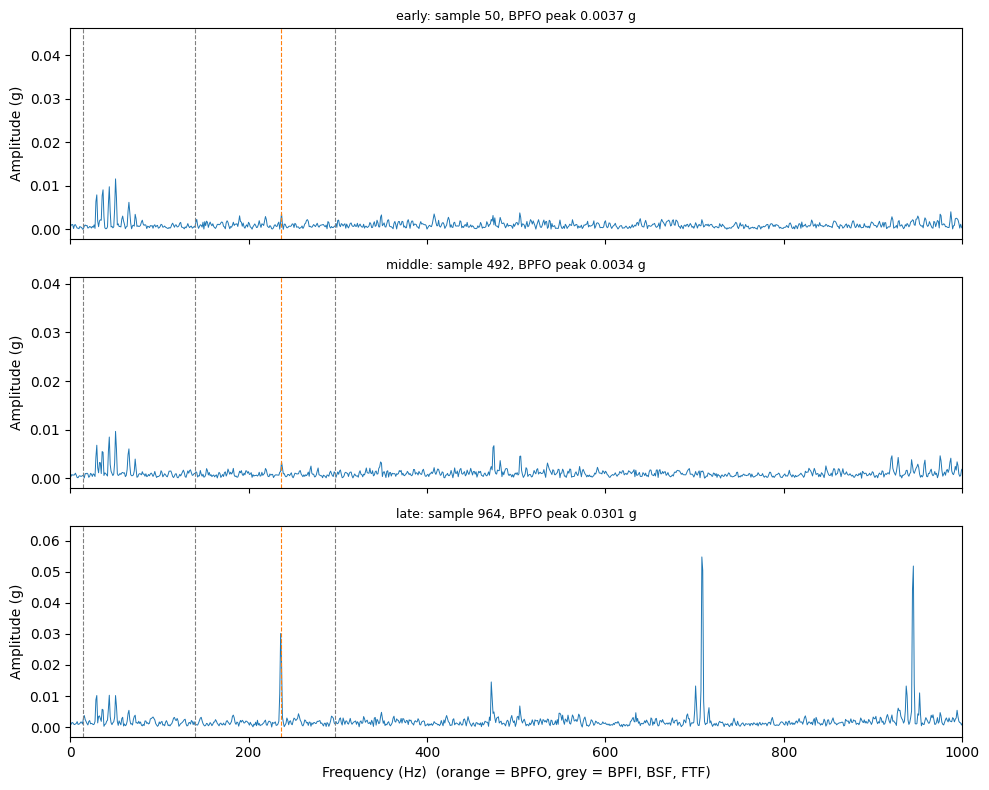

In [5]:
# ---- Colab cell 2: spectra early vs late, with defect frequencies marked ----
import matplotlib.pyplot as plt
from bearing_features import list_snapshot_files, load_snapshot
from spectrum import amplitude_spectrum, defect_frequencies, band_peak

# Uses TEST, TEST_DIR and features from the setup/features cells
# CHANNEL and FAULT come from the FAILED table in the setup cell
files = list_snapshot_files(TEST_DIR)
defects = defect_frequencies()
print({k: round(v, 1) for k, v in defects.items()})

picks = {"early": 50, "middle": len(files) // 2, "late": len(files) - 20}
fig, axes = plt.subplots(len(picks), 1, figsize=(10, 8), sharex=True)
for ax, (label, i) in zip(axes, picks.items()):
    freqs, amp = amplitude_spectrum(load_snapshot(files[i])[:, CHANNEL])
    ax.plot(freqs, amp, lw=0.7)
    for name, f in defects.items():
        ax.axvline(f, ls="--", lw=0.8, color="C1" if name == "BPFO" else "grey")
    ax.set_title(f"{label}: sample {i}, BPFO peak {band_peak(freqs, amp, defects['BPFO']):.4f} g", fontsize=9)
    ax.set_ylabel("Amplitude (g)")
axes[-1].set_xlim(0, 1000)
axes[-1].set_xlabel("Frequency (Hz)  (orange = BPFO, grey = BPFI, BSF, FTF)")
plt.tight_layout()
plt.show()

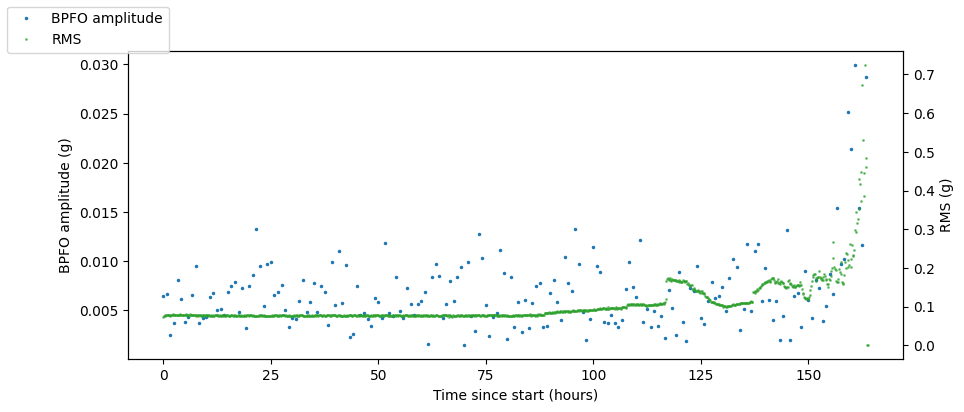

In [6]:
# ---- Colab cell 3: fault-frequency amplitude over the whole test (every 5th file, a few minutes) ----
import os
import numpy as np
from data_quality import file_times

step = 5
idx, peaks = [], []
for i in range(0, len(files), step):
    try:
        data = load_snapshot(files[i])
    except ValueError:   # truncated file (see data quality check): skip it
        print("Skipped", os.path.basename(files[i]))
        continue
    freqs, amp = amplitude_spectrum(data[:, CHANNEL])
    idx.append(i)
    peaks.append(band_peak(freqs, amp, defects[FAULT]))

# Real elapsed time from file names (the interval is not constant, e.g. test 1 has gaps)
t0 = file_times(files[:1])[0]
hours = (file_times([files[i] for i in idx]) - t0).dt.total_seconds() / 3600
rms_hours = (file_times(features["file"]) - t0).dt.total_seconds() / 3600

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(hours, peaks, ".", ms=3, label=f"{FAULT} amplitude")   # points, not lines: test 1 has long gaps
ax1.set_ylabel(f"{FAULT} amplitude (g)")
ax1.set_xlabel("Time since start (hours)")
ax2 = ax1.twinx()
ax2.plot(rms_hours, features[f"rms_{CHANNEL + 1}"].values, ".", ms=2, color="C2", alpha=0.6, label="RMS")
ax2.set_ylabel("RMS (g)")
fig.legend(loc="upper left")
plt.show()

## 5. Trends, smoothing and over/underfitting (week 3)
Test 2 only (uses a 10-minute time axis).

In [7]:
# ---- Colab cell 2: tidy the test 2 features and build a time axis ----
import numpy as np
import matplotlib.pyplot as plt
from trends import moving_average, spline_smooth, knn_smooth, choose_k, health_stages, remaining_life

# Uses `features` (test 2) from the features cell. The last file can be near-empty,
# which shows up as NaN or a sudden jump: look at the tail, then drop bad rows.
print(features.tail(3)[["file", "rms_1", "kurtosis_1"]])
df = features.dropna().copy()
hours = df.index.to_numpy() * 10 / 60      # test 2 snapshots are 10 min apart
rms, kurt = df["rms_1"].to_numpy(), df["kurtosis_1"].to_numpy()   # bearing 1

                       file     rms_1  kurtosis_1
sample                                           
981     2004.02.19.06.02.39  0.483835    7.891755
982     2004.02.19.06.12.39  0.002103    6.637513
983     2004.02.19.06.22.39  0.001533    1.390226


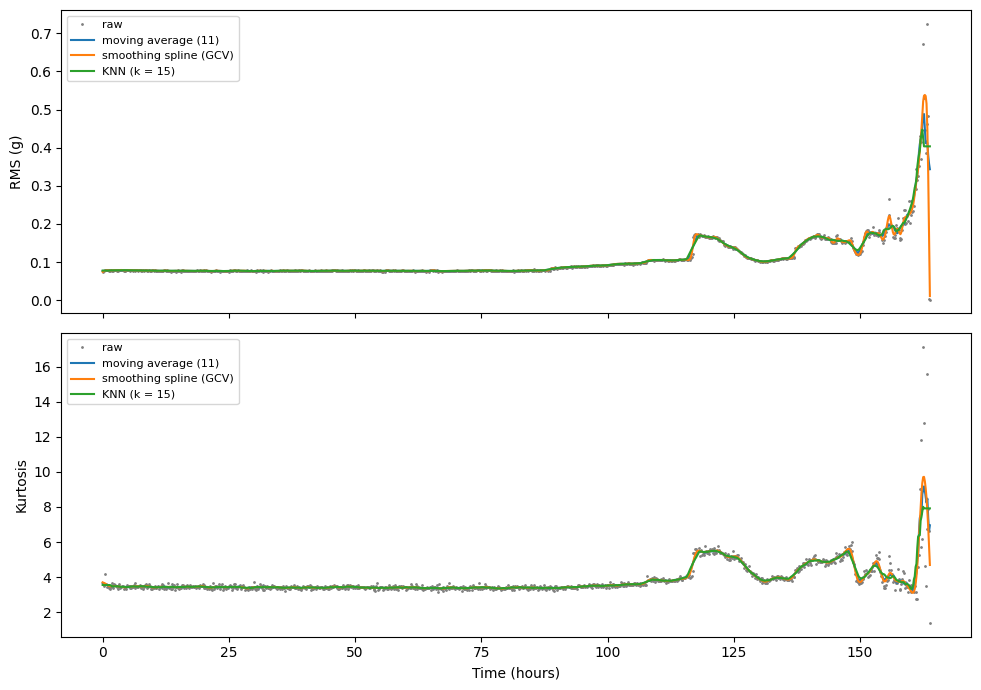

In [8]:
# ---- Colab cell 3: three smoothers on RMS and kurtosis ----
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, y, name in zip(axes, [rms, kurt], ["RMS (g)", "Kurtosis"]):
    ax.plot(hours, y, ".", ms=2, color="grey", label="raw")
    ax.plot(hours, moving_average(y, 11), label="moving average (11)")
    ax.plot(hours, spline_smooth(hours, y), label="smoothing spline (GCV)")
    ax.plot(hours, knn_smooth(hours, y, 15), label="KNN (k = 15)")
    ax.set_ylabel(name)
    ax.legend(fontsize=8)
axes[-1].set_xlabel("Time (hours)")
plt.tight_layout()
plt.show()

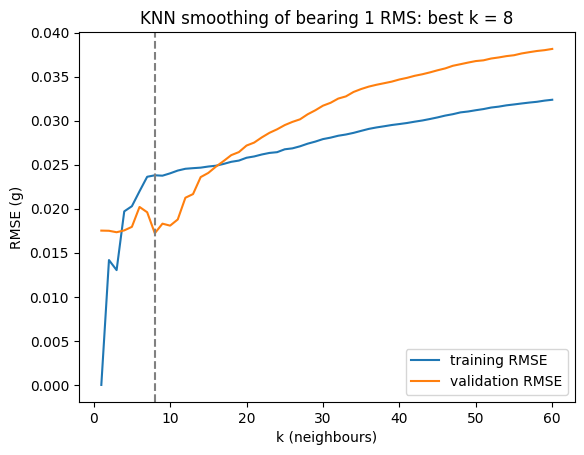

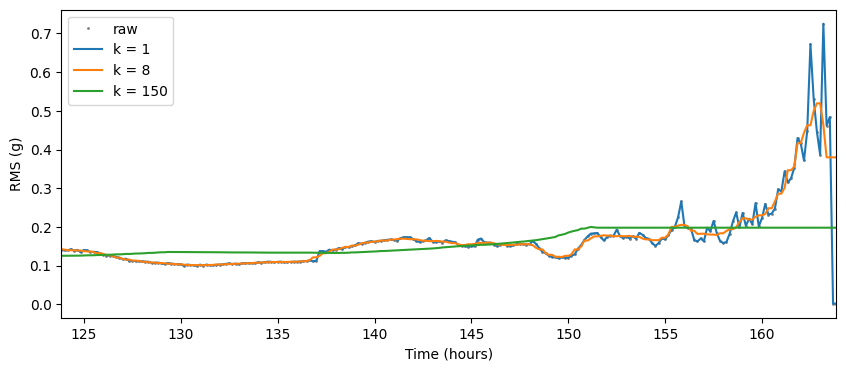

In [9]:
# ---- Colab cell 4: choose k by training vs validation error (over/underfitting) ----
k_best, scores = choose_k(hours, rms)
plt.plot(scores["k"], scores["train"], label="training RMSE")
plt.plot(scores["k"], scores["val"], label="validation RMSE")
plt.axvline(k_best, ls="--", color="grey")
plt.xlabel("k (neighbours)")
plt.ylabel("RMSE (g)")
plt.title(f"KNN smoothing of bearing 1 RMS: best k = {k_best}")
plt.legend()
plt.show()

# Same plot in words: k = 1 overfits (zero training error), large k underfits
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hours, rms, ".", ms=2, color="grey", label="raw")
for k in [1, k_best, 150]:
    ax.plot(hours, knn_smooth(hours, rms, k), label=f"k = {k}")
ax.set_xlim(hours[-1] - 40, hours[-1])   # zoom on the failure, where it matters
ax.set_xlabel("Time (hours)")
ax.set_ylabel("RMS (g)")
ax.legend()
plt.show()

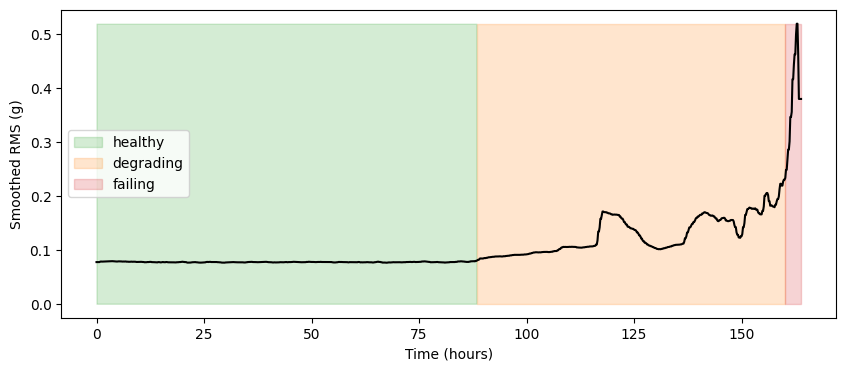

       count        min         max
stage                              
0        531  75.500000  163.833333
1        430   3.833333   75.333333
2         23   0.000000    3.666667


In [10]:
# ---- Colab cell 5: health stages and remaining life (targets for week 5 models) ----
df["rms_smooth"] = knn_smooth(hours, rms, k_best)
df["kurt_smooth"] = knn_smooth(hours, kurt, k_best)
df["stage"] = health_stages(df["rms_smooth"])
df["rul_hours"] = remaining_life(hours)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hours, df["rms_smooth"], color="k")
for s, c in zip([0, 1, 2], ["C2", "C1", "C3"]):
    on = df["stage"].to_numpy() == s
    ax.fill_between(hours, 0, df["rms_smooth"].max(), where=on, color=c, alpha=0.2,
                    label=["healthy", "degrading", "failing"][s])
ax.set_xlabel("Time (hours)")
ax.set_ylabel("Smoothed RMS (g)")
ax.legend()
plt.show()

print(df.groupby("stage")["rul_hours"].agg(["count", "min", "max"]))
df.to_csv("/content/repo/data/labels_2nd_test.csv")   # targets for the week 5 models

## 6. Performance and optimisation (week 2.1)
Run with `TEST = "2nd_test"`.

In [11]:
# ---- Colab cell P1: load the line profiler ----
!pip install --quiet line_profiler
%load_ext line_profiler

In [15]:
# ---- Colab cell P2: settings and imports ----
N_PROFILE = 20                             # snapshots used for profiling (each ~0.5 MB of text)
SIZES = [100, 200, 400, 800, 984]          # snapshots used for the extrapolation scaling test
import glob, os, time, timeit, tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bearing_features import (list_snapshot_files, load_snapshot, snapshot_features,
                              snapshot_features_fast, extract_features)
from rul_models import extrapolate_rul, extrapolate_rul_fast, trailing_mean

files = list_snapshot_files(TEST_DIR)
data = load_snapshot(files[0])
N, n_ch = data.shape
print(f"{len(files)} files, each {N} samples x {n_ch} channels, "
      f"{os.path.getsize(files[0]) / 1e6:.2f} MB of text")

984 files, each 20480 samples x 4 channels, 0.56 MB of text


In [16]:
# ---- Colab cell P3: where does feature extraction spend its time? (line profiler) ----
# In plain words: the profiler times every line of extract_features. Expect most of the time
# in load_snapshot (reading and parsing text from Drive), not in the maths. That tells us
# which part is worth speeding up (Amdahl's law: halving a part that is 10 % of the run
# saves only 5 %).
%lprun -f extract_features extract_features(files[:N_PROFILE])

largest relative difference: 7.605106078914094e-14
load one snapshot (text parse)    16.02
features, original                 3.91
features, vectorised               3.04 (ms per snapshot)
Whole test, original:   19.6 s
Whole test, vectorised: 18.8 s
Read cached CSV:        5 ms


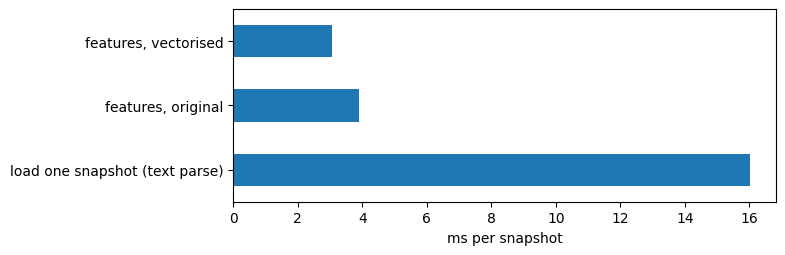

In [17]:
# ---- Colab cell P4: timing, original vs vectorised features, and the cache ----
# In plain words: the same three numbers per snapshot, computed two ways. The original loops
# over channels and uses x**4; the fast version does all channels at once and uses c2*c2.
# Both give identical values (checked here and in the tests). Then the whole-test cost
# of rebuilding features from raw files is compared with reading the cached CSV.
slow, fast = snapshot_features(data), snapshot_features_fast(data)
print("largest relative difference:",
      max(abs(fast[k] - slow[k]) / abs(slow[k]) for k in slow))

def per_call(stmt, number=20):
    """Best of 5 repeats, seconds per call (like %timeit)."""
    return min(timeit.repeat(stmt, number=number, repeat=5)) / number

t_load = per_call(lambda: load_snapshot(files[0]), number=5)
t_slow = per_call(lambda: snapshot_features(data))
t_fast = per_call(lambda: snapshot_features_fast(data))
cache = glob.glob("/content/repo/data/features_2nd_test.csv") + glob.glob(
    "/content/drive/MyDrive/MMA3001/MMA3001_Project/**/features_2nd_test.csv", recursive=True)
t_cache = per_call(lambda: pd.read_csv(cache[0], index_col=0), number=5)

timing = pd.Series({"load one snapshot (text parse)": t_load,
                    "features, original": t_slow,
                    "features, vectorised": t_fast}) * 1000
print(timing.round(2).to_string(), "(ms per snapshot)")
print(f"Whole test, original:   {len(files) * (t_load + t_slow):.1f} s")
print(f"Whole test, vectorised: {len(files) * (t_load + t_fast):.1f} s")
print(f"Read cached CSV:        {t_cache * 1000:.0f} ms")
timing.plot.barh(figsize=(7, 2.5))
plt.xlabel("ms per snapshot")
plt.show()

In [18]:
# ---- Colab cell P5: FLOPs and arithmetic intensity of the feature maths (week 2.1.6) ----
# In plain words: count the arithmetic and the bytes moved for the vectorised version,
# per sample per channel. Each NumPy step reads (and often writes) a whole 8-byte array:
#   x*x (1 FLOP, 16 B), mean (1, 8), mean (1, 8), x-mean (1, 16), c*c (1, 16),
#   mean (1, 8), c2*c2 (1, 16), mean (1, 8), abs (0, 16), max (1, 8)
# = about 9 FLOPs and 120 bytes, so A_I = 9/120 = 0.075 FLOP/byte. That is far below the
# Colab machine balance (~64 GFLOP/s / ~17 GB/s = ~4 FLOP/byte), so the maths is
# bandwidth-bound: it waits on memory, not on the processor. One snapshot is
# 20480 x 4 x 8 B = 655 kB, bigger than L2 cache, so every pass goes out to L3/RAM.
FLOP_PER_SAMPLE, BYTES_PER_SAMPLE = 9, 120
flops = FLOP_PER_SAMPLE * N * n_ch
moved = BYTES_PER_SAMPLE * N * n_ch
print(f"{flops / 1e6:.2f} MFLOP and {moved / 1e6:.1f} MB moved per snapshot")
print(f"arithmetic intensity = {flops / moved:.3f} FLOP/byte")
print(f"achieved: {flops / t_fast / 1e9:.2f} GFLOP/s, {moved / t_fast / 1e9:.1f} GB/s")
# Compare the GB/s with the course estimate of Colab memory bandwidth: if it is close,
# the only further speed-up would be fewer passes (e.g. a single compiled loop, Numba).

0.74 MFLOP and 9.8 MB moved per snapshot
arithmetic intensity = 0.075 FLOP/byte
achieved: 0.24 GFLOP/s, 3.2 GB/s


In [19]:
# ---- Colab cell P6: memory, peak allocation per snapshot and data sizes ----
# In plain words: how much extra memory each version needs while it runs (temporary arrays),
# and how much the feature cache shrinks the data the models need. Expect the vectorised
# version to need more (it keeps whole-snapshot temporaries for all channels at once):
# speed is bought with memory, a trade-off worth one sentence in the report.
for name, fn in [("original", snapshot_features), ("vectorised", snapshot_features_fast)]:
    tracemalloc.start()
    fn(data)
    peak_mb = tracemalloc.get_traced_memory()[1] / 1e6
    tracemalloc.stop()
    print(f"features, {name}: peak {peak_mb:.1f} MB extra")
raw_mb = sum(os.path.getsize(f) for f in files) / 1e6
print(f"raw text: {raw_mb:.0f} MB, feature CSV: {os.path.getsize(cache[0]) / 1e6:.2f} MB")

features, original: peak 0.3 MB extra
features, vectorised: peak 2.0 MB extra
raw text: 545 MB, feature CSV: 0.20 MB


largest difference: 1.01e-08 h
      loop_s  running_sums_s   speed_up
n                                      
100  0.00764         0.00011   72.04461
200  0.01669         0.00012  135.49035
400  0.03471         0.00014  246.27185
800  0.07048         0.00018  390.33694
984  0.08578         0.00020  439.70323


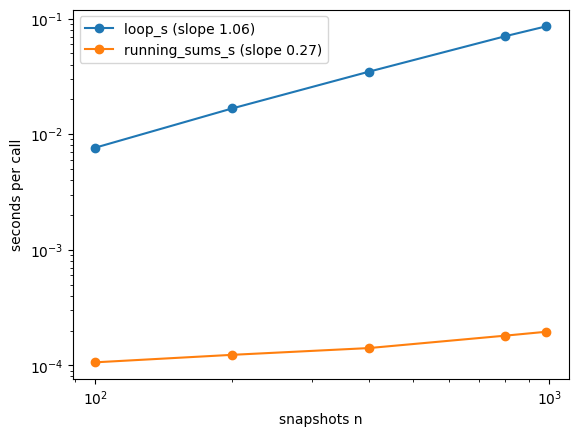

In [20]:
# ---- Colab cell P7: trend extrapolation, loop vs running sums (scaling) ----
# In plain words: the loop version refits a straight line at every snapshot with np.polyfit;
# the fast version gets the same least-squares line from running sums. First check they agree,
# then time both on the first n snapshots of the real RMS record. On a log-log plot the slope
# is the growth rate: about 1 means time doubles when n doubles.
feat = pd.read_csv(cache[0], index_col=0).dropna()
hours_all = feat.index.to_numpy() * 10 / 60
rms_all = trailing_mean(feat["rms_1"].to_numpy(), 6)
threshold = 3 * rms_all[:100].mean()
a = extrapolate_rul(hours_all, rms_all, threshold, 10, max_rul=1000)
b = extrapolate_rul_fast(hours_all, rms_all, threshold, 10, max_rul=1000)
print(f"largest difference: {np.abs(a - b).max():.2e} h")   # rounding only (week 2.2)

rows = []
for n in SIZES:
    t_, y_ = hours_all[:n], rms_all[:n]
    rows.append({"n": n,
                 "loop_s": per_call(lambda: extrapolate_rul(t_, y_, threshold, 10), number=1),
                 "running_sums_s": per_call(lambda: extrapolate_rul_fast(t_, y_, threshold, 10))})
scaling = pd.DataFrame(rows).set_index("n")
scaling["speed_up"] = scaling["loop_s"] / scaling["running_sums_s"]
print(scaling.round(5))
for col in ["loop_s", "running_sums_s"]:
    slope = np.polyfit(np.log(scaling.index), np.log(scaling[col]), 1)[0]
    plt.loglog(scaling.index, scaling[col], "o-", label=f"{col} (slope {slope:.2f})")
plt.xlabel("snapshots n")
plt.ylabel("seconds per call")
plt.legend()
plt.show()

In [21]:
# ---- Colab cell P8: save the numbers for the report ----
summary = pd.DataFrame({
    "original": [1000 * t_slow, len(files) * (t_load + t_slow), 1000 * scaling["loop_s"].iloc[-1]],
    "selected": [1000 * t_fast, len(files) * (t_load + t_fast), 1000 * scaling["running_sums_s"].iloc[-1]]},
    index=["features per snapshot (ms)", "rebuild all features (s)", "extrapolation, 1 setting (ms)"])
summary["speed_up"] = summary["original"] / summary["selected"]
os.makedirs("/content/repo/data", exist_ok=True)
summary.round(3).to_csv("/content/repo/data/performance_2nd_test.csv")
summary.round(2)

,original,selected,speed_up
features per snapshot (ms),3.91,3.04,1.28
rebuild all features (s),19.61,18.76,1.05
"extrapolation, 1 setting (ms)",85.78,0.20,439.70


In [35]:
# ---- Main.ipynb cell T3: unpack test 3 from IMS.zip and build its features (once, about 10 min) ----
# In plain words: the full test 3 is already inside IMS.zip on Drive (6,324 files, although
# the IMS readme says 4,448). It is unpacked onto Colab's own disk, which is also faster to
# read than Drive, turned into the usual feature table, and saved to data/ and Drive.
import os, glob, zipfile, shutil, time
from bearing_features import list_snapshot_files, extract_features

OUT = "/content/ims3"
if not glob.glob(f"{OUT}/**/2004.*", recursive=True):
    os.makedirs(OUT, exist_ok=True)
    with zipfile.ZipFile(f"{PROJECT}/IMS.zip") as z:
        z.extract("IMS/3rd_test.rar", OUT)
    !apt-get -qq install -y unrar > /dev/null
    !unrar x -o+ -inul "{OUT}/IMS/3rd_test.rar" "{OUT}/"
    os.remove(f"{OUT}/IMS/3rd_test.rar")                  # free the disk space
folder = os.path.dirname(sorted(glob.glob(f"{OUT}/**/2004.*", recursive=True))[0])
files3 = list_snapshot_files(folder)
print(folder, "->", len(files3), "files")                  # expect 6324
CSV3 = "/content/repo/data/features_3rd_test.csv"
start = time.perf_counter()
feat3 = extract_features(files3, save_to=CSV3)
print(f"{len(feat3)} snapshots in {time.perf_counter() - start:.0f} s")
shutil.copy(CSV3, f"{PROJECT}/features_3rd_test.csv")     # replaces the old partial table
feat3.tail(3)

/content/ims3/4th_test/txt -> 6324 files
6324 snapshots in 115 s


,file,rms_1,kurtosis_1,peak_1,rms_2,kurtosis_2,peak_2,rms_3,kurtosis_3,peak_3,rms_4,kurtosis_4,peak_4
sample,,,,,,,,,,,,,
6321,2004.04.18.02.22.55,0.147181,3.553022,0.754,0.250657,2.769487,0.864,0.590047,15.661554,5.000,0.279863,3.030495,1.104
6322,2004.04.18.02.32.55,0.154482,4.093748,0.933,0.257200,3.658376,1.292,0.758765,10.059903,5.000,0.282174,2.514097,0.969
6323,2004.04.18.02.42.55,0.001912,4.299890,0.005,0.002789,3.330606,0.007,0.003966,1.173573,0.007,0.001850,4.016778,0.005


## 7. Publish

In [40]:
# ---- Publish to GitHub: docs, tests, this notebook, commit, push ----
# Save the notebook first (Ctrl+S) so the latest version is copied.
MSG = "adding and unpacking test 3"                 # edit this each time
NB = "Main.ipynb"
import glob
hits = glob.glob(f"/content/drive/MyDrive/**/{NB}", recursive=True)
assert hits, f"{NB} not found in Drive: check the name in the title bar, then File > Save"
%cd /content/repo
!mkdir -p notebooks && cp "{hits[0]}" notebooks/
!pdoc --math ./src/*.py -o ./docs
!PYTHONPATH=src pytest tests -v > test_report.txt
!tail -1 test_report.txt
!git add -A
!git commit -q -m "{MSG}"
!git pull -q --rebase -X theirs origin main
!git push -q origin main

/content/repo
============================== 48 passed in 3.38s ==============================
